<a href="https://colab.research.google.com/github/tyangdon/Opportunity_Execelerate_file-/blob/main/Excelerate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import re
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

In [ ]:
df = pd.read_csv('/content/#Opportunity Data - Sheet1.csv', na_values=['N/A', 'NA', ' ', 'None'], keep_default_na=True)
print("Data set shape is ", df.shape)
df.head()

Data set shape is  (5733, 33)


,pk,opportunity_id,Badge,CareerAddOn,category,code,Cohort,created_at,currency_type,current_editor,DropoutTransaction,duration,duration_type,Eligibility,fee,image_link,is_archived,is_auto_approve,last_date_to_apply,location,long_description,microscholarship,modified_at,name,NotStartedTransaction,Panellist,Reward,role,role_responsibility,short_description,summary,Testimonial,tracking_questions
0,Opportunity#,Opportunity#000000000GBD0AX3Z6VYRG7R75,"{""sk"":""Badge#000000000G87VEXNYKKKTJTKE9"",""ref_...",NaN,Competition,M636023,"{""sk"":""Cohort#000000000GWJV80KJCAEP0JMCF"",""ref...",1.66E+12,USD,amrit@vempower.org,NaN,300,minutes,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://www.clipartkey.com/mpngs/m/56-563364_b...,TRUE,TRUE,1.69E+12,NaN,"Your future is in your hands, truly. Ideate an...",500,1.69E+12,Mini Saga 3.0,NaN,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",NaN,NaN,Express yourself in 50-words!,cc,"{""sk"":""Testimonial#0000000010RY2C6SEZQ3HGA9CM""...",NaN
1,Opportunity#,Opportunity#000000000GFKZ4N696ZF8V2WM8,"{""sk"":""Badge#000000000GAR6YSZ2B71HZJPM3"",""ref_...","{""sk"":""CareerAddOn#000000000G8FT85VQ6BFCT0M0K""...",Career,A463411,"{""sk"":""Cohort#000000000GMAPG3GQV19H288WA"",""ref...",1.66E+12,USD,NaN,NaN,1,years,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://encrypted-tbn0.gstatic.com/images?q=tb...,TRUE,TRUE,1.69E+12,NaN,At GlobalShala we believe that experiential le...,100,1.69E+12,Virtual Internship Facilitator,NaN,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",Facilitator,<html><body><ul><li>Leading and mentoring a gr...,In this role you be impacting young lives whil...,NaN,"{""sk"":""Testimonial#0000000010D46TNR53M1VB684P""...",NaN
2,Opportunity#,Opportunity#0000000010ZFE0ZS22FA3Q62R4,NaN,NaN,Career,A8848RT,"{""sk"":""Cohort#0000000010NSPP283G9WKVMTF1"",""cre...",1.71E+12,NaN,NaN,NaN,30,weeks,NaN,0,https://excelerate-profile-dev.s3.ap-south-1.a...,NaN,FALSE,1.56E+12,WFM,NaN,0,1.71E+12,Careerwishlist Automation 1710333189352,NaN,NaN,NaN,NaN,Testing and debugging,"Short Description, Explore hands-on defensive ...",NaN,NaN,NaN
3,Opportunity#,Opportunity#000000000GG34EPWZAJ6BDPQKP,"{""sk"":""Badge#000000000GGQG1DZ2TSSHR55G9"",""ref_...",NaN,Internship,I882052,"{""sk"":""Cohort#000000000G5NWDEFZY8WZMG5TM"",""ref...",1.67E+12,USD,NaN,NaN,20,minutes,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://excelerateuserprofile.s3.ap-south-1.am...,TRUE,TRUE,1.70E+12,NaN,"In this internship, you will help your sponsor...",1000,1.69E+12,Digital Marketing - Demo,NaN,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",Social Media Analyst,NaN,Explore the best practices and proven strategi...,NaN,"{""sk"":""Testimonial#00000000103FKJAPTGDJ3E9MBV""...",NaN
4,Opportunity#,Opportunity#000000000GQHDFWJ9R1HQJ4WTE,NaN,NaN,Event,E307640,"{""sk"":""Cohort#000000000GG395GEZJKV7T5ZSG"",""ref...",1.66E+12,USD,{},NaN,3,years,"{""sk"":""Eligibility#000000000GF6KQ9RF2HK4CE5K9""...",0,https://excelerateuserprofile.s3.ap-south-1.am...,FALSE,TRUE,1.78E+12,NaN,As technologies such as social media apps and ...,500,1.78E+12,Humanizing Technology: An Introduction to User...,NaN,"{""sk"":""Panellist#000000000GJZDTG56N34DZP205"",""...","{""sk"":""Reward#000000000GPWPT65H92PVBCQ43"",""ref...",NaN,NaN,Students will learn the fundamentals of user e...,NaN,"{""sk"":""Testimonial#0000000010HB3W8EZW550FT6M1""...","{""code"":""Team"",""is_required_for_badge_award"":""..."


In [ ]:
# make into snake case
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')
df= df.rename(columns= {'CareerAddOn': 'career_add_on', 'dropouttransaction': 'dropout_transaction', 'microscholarship':'micro_scholarship',
                        'notstartedtransaction':'not_started_transaction'})
df.head(2)

,pk,opportunity_id,badge,careeraddon,category,code,cohort,created_at,currency_type,current_editor,dropout_transaction,duration,duration_type,eligibility,fee,image_link,is_archived,is_auto_approve,last_date_to_apply,location,long_description,micro_scholarship,modified_at,name,not_started_transaction,panellist,reward,role,role_responsibility,short_description,summary,testimonial,tracking_questions
0,Opportunity#,Opportunity#000000000GBD0AX3Z6VYRG7R75,"{""sk"":""Badge#000000000G87VEXNYKKKTJTKE9"",""ref_...",NaN,Competition,M636023,"{""sk"":""Cohort#000000000GWJV80KJCAEP0JMCF"",""ref...",1.66E+12,USD,amrit@vempower.org,NaN,300,minutes,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://www.clipartkey.com/mpngs/m/56-563364_b...,TRUE,TRUE,1.69E+12,NaN,"Your future is in your hands, truly. Ideate an...",500,1.69E+12,Mini Saga 3.0,NaN,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",NaN,NaN,Express yourself in 50-words!,cc,"{""sk"":""Testimonial#0000000010RY2C6SEZQ3HGA9CM""...",NaN
1,Opportunity#,Opportunity#000000000GFKZ4N696ZF8V2WM8,"{""sk"":""Badge#000000000GAR6YSZ2B71HZJPM3"",""ref_...","{""sk"":""CareerAddOn#000000000G8FT85VQ6BFCT0M0K""...",Career,A463411,"{""sk"":""Cohort#000000000GMAPG3GQV19H288WA"",""ref...",1.66E+12,USD,NaN,NaN,1,years,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://encrypted-tbn0.gstatic.com/images?q=tb...,TRUE,TRUE,1.69E+12,NaN,At GlobalShala we believe that experiential le...,100,1.69E+12,Virtual Internship Facilitator,NaN,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",Facilitator,<html><body><ul><li>Leading and mentoring a gr...,In this role you be impacting young lives whil...,NaN,"{""sk"":""Testimonial#0000000010D46TNR53M1VB684P""...",NaN


In [ ]:
print("any duplicated value : ",df.duplicated().sum())
missing_pct = df.isnull().mean() * 100
missing_pct

any duplicated value :  0


,0
pk,0.000000
opportunity_id,0.000000
badge,6.401535
careeraddon,84.161870
category,0.034886
code,0.052329
cohort,0.366300
created_at,0.052329
currency_type,5.965463
current_editor,96.214896


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5733 entries, 0 to 5732
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   pk                       5733 non-null   object
 1   opportunity_id           5733 non-null   object
 2   badge                    5366 non-null   object
 3   careeraddon              908 non-null    object
 4   category                 5731 non-null   object
 5   code                     5730 non-null   object
 6   cohort                   5712 non-null   object
 7   created_at               5730 non-null   object
 8   currency_type            5391 non-null   object
 9   current_editor           217 non-null    object
 10  dropout_transaction      13 non-null     object
 11  duration                 5731 non-null   object
 12  duration_type            5729 non-null   object
 13  eligibility              5382 non-null   object
 14  fee                      5731 non-null  

# Data Cleaning



In [ ]:
# colums to drop due to huge missing data
cols_to_drop = [
    'dropout_transaction',
    'not_started_transaction',
    'summary',
    'current_editor',
    'is_archived'
]

df= df.drop(columns=cols_to_drop)
df.head()

,pk,opportunity_id,badge,careeraddon,category,code,cohort,created_at,currency_type,duration,duration_type,eligibility,fee,image_link,is_auto_approve,last_date_to_apply,location,long_description,micro_scholarship,modified_at,name,panellist,reward,role,role_responsibility,short_description,testimonial,tracking_questions
0,Opportunity#,Opportunity#000000000GBD0AX3Z6VYRG7R75,"{""sk"":""Badge#000000000G87VEXNYKKKTJTKE9"",""ref_...",NaN,Competition,M636023,"{""sk"":""Cohort#000000000GWJV80KJCAEP0JMCF"",""ref...",1.66E+12,USD,300,minutes,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://www.clipartkey.com/mpngs/m/56-563364_b...,TRUE,1.69E+12,NaN,"Your future is in your hands, truly. Ideate an...",500,1.69E+12,Mini Saga 3.0,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",NaN,NaN,Express yourself in 50-words!,"{""sk"":""Testimonial#0000000010RY2C6SEZQ3HGA9CM""...",NaN
1,Opportunity#,Opportunity#000000000GFKZ4N696ZF8V2WM8,"{""sk"":""Badge#000000000GAR6YSZ2B71HZJPM3"",""ref_...","{""sk"":""CareerAddOn#000000000G8FT85VQ6BFCT0M0K""...",Career,A463411,"{""sk"":""Cohort#000000000GMAPG3GQV19H288WA"",""ref...",1.66E+12,USD,1,years,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://encrypted-tbn0.gstatic.com/images?q=tb...,TRUE,1.69E+12,NaN,At GlobalShala we believe that experiential le...,100,1.69E+12,Virtual Internship Facilitator,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",Facilitator,<html><body><ul><li>Leading and mentoring a gr...,In this role you be impacting young lives whil...,"{""sk"":""Testimonial#0000000010D46TNR53M1VB684P""...",NaN
2,Opportunity#,Opportunity#0000000010ZFE0ZS22FA3Q62R4,NaN,NaN,Career,A8848RT,"{""sk"":""Cohort#0000000010NSPP283G9WKVMTF1"",""cre...",1.71E+12,NaN,30,weeks,NaN,0,https://excelerate-profile-dev.s3.ap-south-1.a...,FALSE,1.56E+12,WFM,NaN,0,1.71E+12,Careerwishlist Automation 1710333189352,NaN,NaN,NaN,Testing and debugging,"Short Description, Explore hands-on defensive ...",NaN,NaN
3,Opportunity#,Opportunity#000000000GG34EPWZAJ6BDPQKP,"{""sk"":""Badge#000000000GGQG1DZ2TSSHR55G9"",""ref_...",NaN,Internship,I882052,"{""sk"":""Cohort#000000000G5NWDEFZY8WZMG5TM"",""ref...",1.67E+12,USD,20,minutes,"{""sk"":""Eligibility#000000000GNQAM21BYCRBX5Z27""...",0,https://excelerateuserprofile.s3.ap-south-1.am...,TRUE,1.70E+12,NaN,"In this internship, you will help your sponsor...",1000,1.69E+12,Digital Marketing - Demo,NaN,"{""sk"":""Reward#000000000GP9G70RKA2V5WXN5B"",""ref...",Social Media Analyst,NaN,Explore the best practices and proven strategi...,"{""sk"":""Testimonial#00000000103FKJAPTGDJ3E9MBV""...",NaN
4,Opportunity#,Opportunity#000000000GQHDFWJ9R1HQJ4WTE,NaN,NaN,Event,E307640,"{""sk"":""Cohort#000000000GG395GEZJKV7T5ZSG"",""ref...",1.66E+12,USD,3,years,"{""sk"":""Eligibility#000000000GF6KQ9RF2HK4CE5K9""...",0,https://excelerateuserprofile.s3.ap-south-1.am...,TRUE,1.78E+12,NaN,As technologies such as social media apps and ...,500,1.78E+12,Humanizing Technology: An Introduction to User...,"{""sk"":""Panellist#000000000GJZDTG56N34DZP205"",""...","{""sk"":""Reward#000000000GPWPT65H92PVBCQ43"",""ref...",NaN,NaN,Students will learn the fundamentals of user e...,"{""sk"":""Testimonial#0000000010HB3W8EZW550FT6M1""...","{""code"":""Team"",""is_required_for_badge_award"":""..."


**# Select and display summary statistics for numerical columns**

In [ ]:
# Convert specific numeric columns explicitly
numeric_cols = ['duration', 'fee', 'micro_scholarship']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Describe all numeric columns
df.select_dtypes(include='number').describe()

,duration,fee,micro_scholarship
count,5728.000000,5.728000e+03,5.727000e+03
mean,30.346892,1.047486e+09,8.922746e+04
std,215.079570,7.927746e+10,6.608328e+06
min,0.000000,0.000000e+00,0.000000e+00
25%,12.000000,0.000000e+00,1.000000e+02
50%,30.000000,0.000000e+00,1.200000e+02
75%,30.000000,0.000000e+00,1.200000e+02
max,11334.000000,6.000000e+12,5.000000e+08


**Treat impossible extreme anomalies after finding major outlier from box plot**

In [ ]:
# Convert to numeric
for col in ['fee', 'micro_scholarship', 'duration']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Treat impossible extreme anomalies (> $20,000) as missing data (NaN)
df.loc[df['fee'] > 3000, 'fee'] = np.nan
df.loc[df['micro_scholarship'] > 8000, 'micro_scholarship'] = np.nan
# View rows missing duration_type
df[df['duration_type'].isnull() & df['duration'].notnull()][['name', 'category', 'duration', 'duration_type']]

# Function to normalize durations into total Days
def normalize_duration_days(row):
    val = row['duration']
    unit = str(row['duration_type']).lower()

    if pd.isna(val) or pd.isna(unit):
        return np.nan

    if 'minute' in unit:
        return val / (60 * 24)
    elif 'hour' in unit:
        return val / 24
    elif 'day' in unit:
        return val
    elif 'week' in unit:
        return val * 7
    elif 'month' in unit:
        return val * 30
    elif 'year' in unit:
        return val * 365
    return np.nan

# Create standardized duration column in days
df['duration_in_days'] = df.apply(normalize_duration_days, axis=1)

# Cap extreme outliers (e.g., set upper threshold based on realistic bounds)
# Convert values greater than 1095(3years) to NaN
df['duration_in_days'] = df['duration_in_days'].apply(lambda x: x if x <= 2000 else np.nan)

**To detect Outlier using box plot**

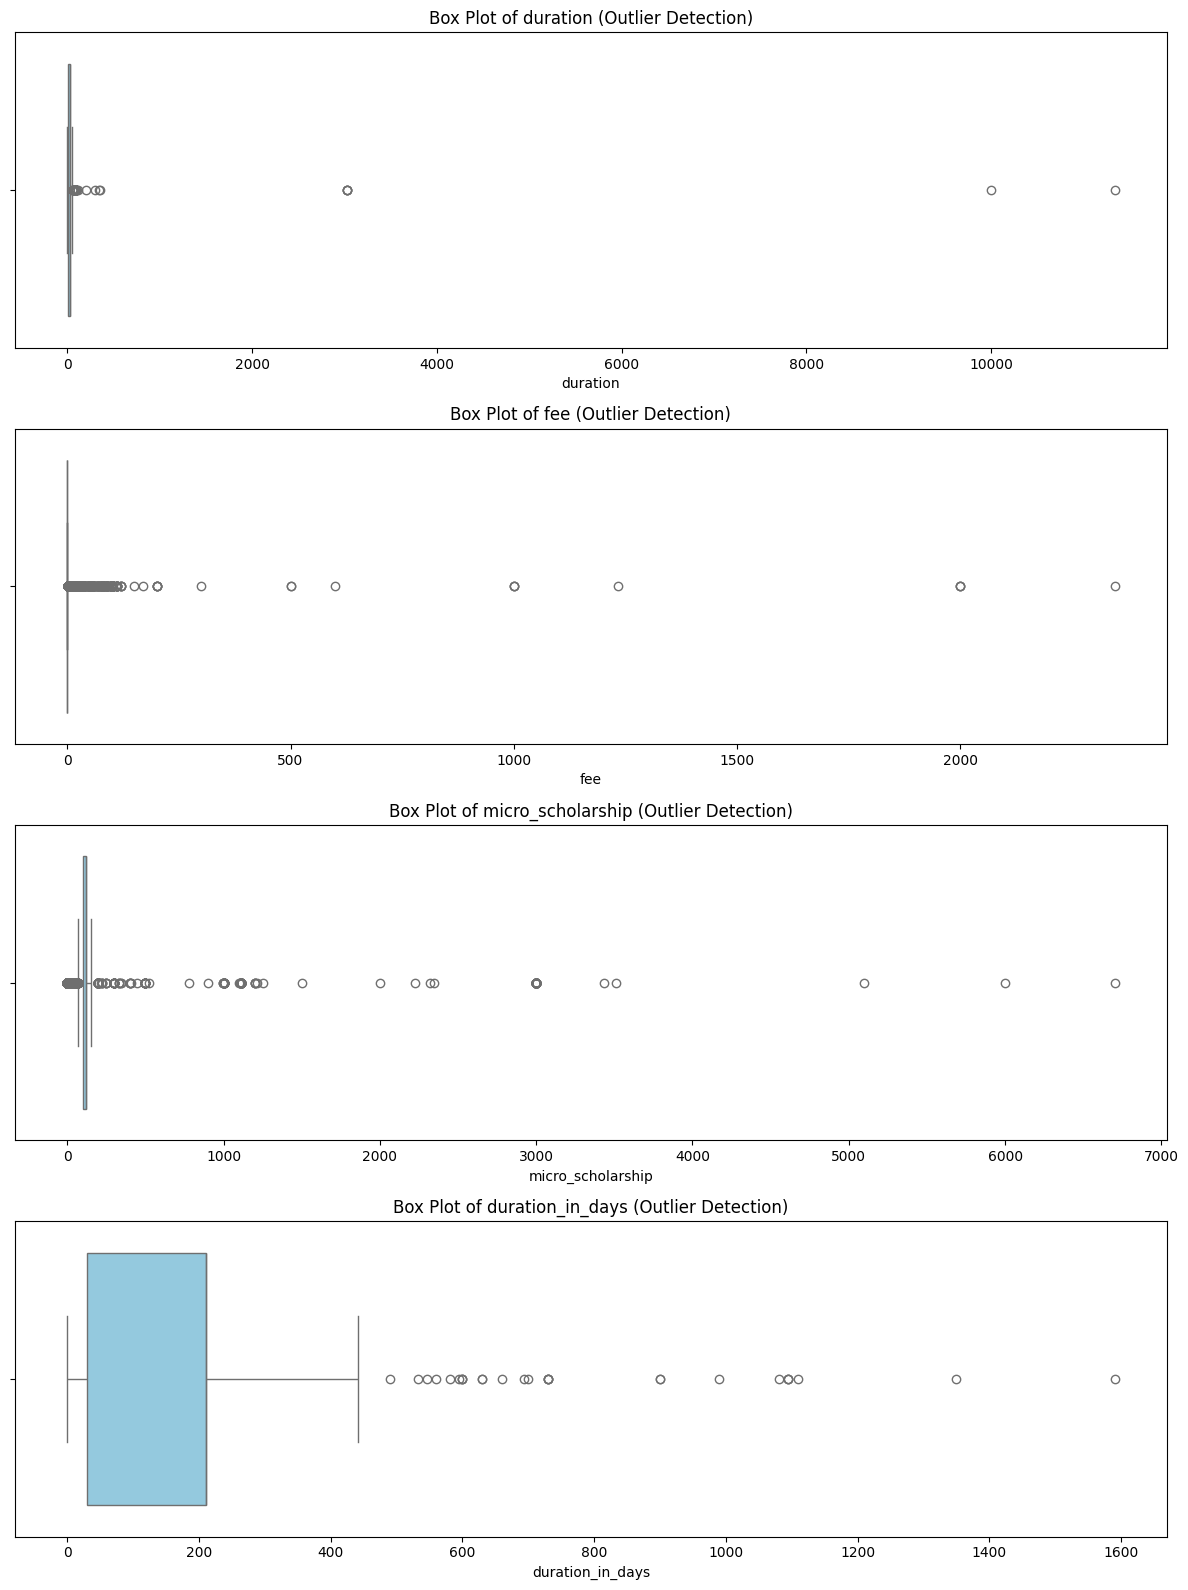

In [ ]:
# Select only numerical columns
num_cols = df.select_dtypes(include=['number']).columns

# Plot box plots for each numerical column
plt.figure(figsize=(12, 4 * len(num_cols)))

for i, col in enumerate(num_cols, 1):
    plt.subplot(len(num_cols), 1, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Box Plot of {col} (Outlier Detection)')
    plt.xlabel(col)

plt.tight_layout()
plt.show()

**Changing timestamp from object into DateTime format**

In [ ]:
date_cols = ['created_at', 'modified_at', 'last_date_to_apply']

for col in date_cols:
    num = pd.to_numeric(df[col], errors='coerce')
    df[col] = pd.to_datetime(num, unit='ms', errors='coerce')

print(df[date_cols].isna().mean())   # should no longer be ~1.0
df[date_cols].head()

created_at            0.001047
modified_at           0.000872
last_date_to_apply    0.001047
dtype: float64


,created_at,modified_at,last_date_to_apply
0,2022-08-08 23:06:40,2023-07-22 04:26:40,2023-07-22 04:26:40
1,2022-08-08 23:06:40,2023-07-22 04:26:40,2023-07-22 04:26:40
2,2024-03-09 16:00:00,2024-03-09 16:00:00,2019-06-08 13:20:00
3,2022-12-02 16:53:20,2023-07-22 04:26:40,2023-11-14 22:13:20
4,2022-08-08 23:06:40,2026-05-28 20:26:40,2026-05-28 20:26:40


In [ ]:
print(df['created_at'].nunique(), "unique values out of", len(df))
print(df['created_at'].dt.time.value_counts().head())
print("starting time :", df['created_at'].min())
print("Ending time :", df['created_at'].max())
print("*******************************************")
print("Starting last_date_to_apply :", df['last_date_to_apply'].min())
print("Ending last_date_to_apply :", df['last_date_to_apply'].max())
print("*******************************************")
print("starting modified_at :", df['modified_at'].min())
print("Ending modified_at :", df['modified_at'].max())

13 unique values out of 5733
created_at
04:26:40    1052
16:00:00     977
22:13:20     797
03:33:20     609
09:46:40     542
Name: count, dtype: int64
starting time : 2022-08-08 23:06:40
Ending time : 2026-05-28 20:26:40
*******************************************
Starting last_date_to_apply : 1970-01-01 00:00:00
Ending last_date_to_apply : 2027-12-28 13:20:00
*******************************************
starting modified_at : 2023-03-28 10:40:00
Ending modified_at : 2026-05-28 20:26:40


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5733 entries, 0 to 5732
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   pk                   5733 non-null   object        
 1   opportunity_id       5733 non-null   object        
 2   badge                5366 non-null   object        
 3   careeraddon          908 non-null    object        
 4   category             5731 non-null   object        
 5   code                 5730 non-null   object        
 6   cohort               5712 non-null   object        
 7   created_at           5727 non-null   datetime64[ns]
 8   currency_type        5391 non-null   object        
 9   duration             5728 non-null   float64       
 10  duration_type        5729 non-null   object        
 11  eligibility          5382 non-null   object        
 12  fee                  5724 non-null   float64       
 13  image_link           5725 non-nul

In [ ]:
df[['long_description', 'short_description']].head()

,long_description,short_description
0,"Your future is in your hands, truly. Ideate an...",Express yourself in 50-words!
1,At GlobalShala we believe that experiential le...,In this role you be impacting young lives whil...
2,NaN,"Short Description, Explore hands-on defensive ..."
3,"In this internship, you will help your sponsor...",Explore the best practices and proven strategi...
4,As technologies such as social media apps and ...,Students will learn the fundamentals of user e...


**Is auto approve**

In [ ]:
# Standardize string representations to boolean or keep as NaN
valid_map = {'TRUE': True, 'FALSE': False, True: True, False: False}

df['is_auto_approve'] = df['is_auto_approve'].map(valid_map)


**Data cleaning for currency_type columns**

In [ ]:
# Standardize currency codes
df['currency_type'] = df['currency_type'].replace({'EURO': 'EUR'})

# Clean out corrupt JSON values by keeping only known valid currencies
valid_currencies = ['USD', 'INR', 'EUR']
df['currency_type'] = df['currency_type'].where(df['currency_type'].isin(valid_currencies), None)

# Verify cleaned value counts
df['currency_type'].value_counts(dropna=False)

,count
currency_type,
USD,4699
INR,355
None,345
EUR,334


**Running a comprehensive, centralized cleaning pass across all categorical and text columns, as well as extracting clean relational IDs from raw JSON string columns**

In [ ]:
# ---------------------------------------------------------
# HELPER FUNCTIONS
# ---------------------------------------------------------
def clean_text_value(val, valid_list=None, invalid_list=None):
    """Strips whitespace and converts corrupted artifacts/metadata to NaN."""
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()

    # Standard metadata/JSON noise patterns
    noise_patterns = [
        r'%22', r'\\""', r'\{\s*%', r'\}', r'\[""', r'\""ct\""', r'\""sk\""'
    ]
    if any(re.search(pat, val_str) for pat in noise_patterns):
        return np.nan

    if invalid_list and val_str in invalid_list:
        return np.nan
    if valid_list and val_str not in valid_list:
        return np.nan

    return val_str

def parse_json_sk(val, prefix=''):
    """Extracts clean ID from JSON strings/dicts while removing surrounding metadata."""
    if pd.isna(val) or not val:
        return np.nan
    try:
        clean_val = val.replace("'", '"') if isinstance(val, str) else val
        data = json.loads(clean_val) if isinstance(clean_val, str) else clean_val
        if isinstance(data, dict):
            sk = str(data.get('sk', ''))
            if prefix and sk.startswith(prefix):
                sk = sk.replace(prefix, '')
            return sk if sk else np.nan
    except Exception:
        pass
    return np.nan

# ---------------------------------------------------------
# 1. CLEAN CATEGORICAL & TEXT METADATA ARTIFACTS
# ---------------------------------------------------------
# Category
valid_categories = ['Internship', 'Career', 'Competition', 'Course', 'Event',
                    'Engagement', 'Masterclass', 'JobSimulation', 'Program', 'Xploreu']
if 'category' in df.columns:
    df['category'] = df['category'].apply(lambda x: clean_text_value(x, valid_list=valid_categories))

# Primary Key (pk)
if 'pk' in df.columns:
    df['pk'] = df['pk'].where(df['pk'].astype(str).str.startswith('Opportunity#', na=False), np.nan)

# Duration Type
unit_map = {
    'weeks': 'week', 'week': 'week',
    'months': 'month', 'month': 'month',
    'hours': 'hour', 'hour': 'hour',
    'days': 'day', 'day': 'day',
    'minutes': 'minute', 'minute': 'minute',
    'years': 'year', 'year': 'year'
}
if 'duration_type' in df.columns:
    df['duration_type'] = df['duration_type'].astype(str).str.lower().str.strip().map(unit_map)

# Image Link (Valid URL Check)
if 'image_link' in df.columns:
    df['image_link'] = df['image_link'].astype(str).str.strip()
    valid_url_mask = df['image_link'].str.startswith(('http://', 'https://'), na=False)
    df['image_link'] = df['image_link'].where(valid_url_mask, np.nan)

# Opportunity Name
invalid_names = [
    'Auto', 'Test', 'Opportunity name', 'Opportunity Name',
    'Actual LMS V3', 'test', 'auto', 'abcd', 'none', 'nan', 'null', ''
]
if 'name' in df.columns:
    df['name'] = df['name'].astype(str).str.strip()
    df['name'] = df['name'].str.replace(r'^Opportunity name[,\-]?\s*', '', regex=True)
    df['name'] = df['name'].apply(lambda x: clean_text_value(x, invalid_list=invalid_names))
    df['name'] = df['name'].where(~df['name'].astype(str).str.contains(r'Automation\s+\d+', regex=True, na=False), np.nan)

# Short Description
invalid_shorts = [
    'Short Description', 'short description', 'Short', 'short', 'SHort',
    'test', 'Test data', 'abc', 's', 'adsfjskvksn', ',skksskks',
    'dhsdoiui', 'dsfsdfsdfdfwefwefewfwdf', 'nan', 'None', 'null', ''
]
if 'short_description' in df.columns:
    df['short_description'] = df['short_description'].astype(str).str.replace(r'<[^>]+>', '', regex=True)
    df['short_description'] = df['short_description'].str.replace(r'^(Short Description)+[,\-]?\s*', '', regex=True, flags=re.IGNORECASE).str.strip()
    df['short_description'] = df['short_description'].apply(lambda x: clean_text_value(x, invalid_list=invalid_shorts))
    df['short_description'] = df['short_description'].apply(lambda x: x if pd.isna(x) or len(str(x)) >= 3 else np.nan)

# Long Description
invalid_longs = [
    'Long Long Long Long Description', 'Long Description', 'long description',
    'Long', 'long', 'test', 'twst', 'ok', 'abcd', 'osndvsv k',
    'Aut officiis molesti', 'Sit quasi saepe earu', 'none', 'nan', 'null', ''
]
if 'long_description' in df.columns:
    df['long_description'] = df['long_description'].astype(str).str.replace('%0A', ' ', regex=False).str.replace('%20', ' ', regex=False)
    df['long_description'] = df['long_description'].str.replace(r'<[^>]+>', '', regex=True).str.strip()
    df['long_description'] = df['long_description'].apply(lambda x: clean_text_value(x, invalid_list=invalid_longs))

# Role
invalid_roles = ['Role', 'Nan', 'None', 'Null', '', 'Efsdc', 'Et Deleniti Non A Ab', 'Velit Culpa Dolore', 'Test', 'Auto']
if 'role' in df.columns:
    df['role'] = df['role'].astype(str).str.strip().str.title()
    df['role'] = df['role'].apply(lambda x: clean_text_value(x, invalid_list=invalid_roles))

# Role Responsibility
invalid_resps = [
    'Testing and debugging', 'Roles and Responsibility', 'Testing Roles an Responsibility',
    'testing1 testing2', 'sksks', 'cdc', 'vdfvdfv', 'Chill', 'test opportunity eligibility',
    'Maxime eaque adipisi', 'nan', 'None', 'Null', ''
]
if 'role_responsibility' in df.columns:
    df['role_responsibility'] = df['role_responsibility'].astype(str).str.replace(r'<[^>]+>', '', regex=True)
    df['role_responsibility'] = df['role_responsibility'].str.replace(r'^Testing\s*(and|Roles\s*an)?\s*Responsibility\s*', '', regex=True, flags=re.IGNORECASE).str.strip()
    df['role_responsibility'] = df['role_responsibility'].apply(lambda x: x.capitalize() if len(x.split()) == 1 else x)
    df['role_responsibility'] = df['role_responsibility'].apply(lambda x: clean_text_value(x, invalid_list=invalid_resps))

# Tracking Questions List
invalid_questions = [
    'ddfgddf, Additional Notes', 'test, Additional Notes', 'testing, Additional Notes',
    'nan', 'None', 'null', ''
]
if 'tracking_questions_list' in df.columns:
    # 1. Clean extra spaces and quotes
    df['tracking_questions_list'] = df['tracking_questions_list'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
    # 2. Filter explicit test question strings
    df['tracking_questions_list'] = df['tracking_questions_list'].apply(lambda x: clean_text_value(x, invalid_list=invalid_questions))
    # 3. Filter entries containing gibberish string fragments
    df['tracking_questions_list'] = df['tracking_questions_list'].where(~df['tracking_questions_list'].astype(str).str.contains(r'ddfgddf|asdf|qwerty', case=False, na=False), np.nan)

# ---------------------------------------------------------
# 2. EXTRACT CLEAN IDs & REMOVE RAW JSON COLUMNS
# ---------------------------------------------------------
json_mappings = {
    'badge': ('badge_id', 'Badge#'),
    'cohort': ('cohort_id', 'Cohort#'),
    'careeraddon': ('career_addon_id', 'CareerAddOn#'),
    'career_add_on': ('career_addon_id', 'CareerAddOn#')
}

for col, (new_col, prefix) in json_mappings.items():
    if col in df.columns:
        df[new_col] = df[col].apply(lambda x: parse_json_sk(x, prefix=prefix))

# Drop all remaining raw unparsed JSON columns
raw_json_cols = [
    'tracking_questions', 'testimonial', 'reward', 'panellist',
    'eligibility', 'badge', 'cohort', 'careeraddon', 'career_add_on'
]
df = df.drop(columns=[c for c in raw_json_cols if c in df.columns])

print("All metadata artifacts, tracking_questions_list, descriptions, roles, and raw JSON fields cleaned successfully!")

All metadata artifacts, tracking_questions_list, descriptions, roles, and raw JSON fields cleaned successfully!


# Imputing missing value

In [ ]:
# Create a copy to preserve raw cleaned state if needed
df_imputed = df.copy()

# ---------------------------------------------------------
# 1. NUMERIC COLUMNS IMPUTATION
# ---------------------------------------------------------
# Missing fees & scholarships usually represent 0
df_imputed['fee'] = df_imputed['fee'].fillna(0)
df_imputed['micro_scholarship'] = df_imputed['micro_scholarship'].fillna(0)

# Impute missing duration using category median, falling back to global median
if 'duration_in_days' in df_imputed.columns:
    df_imputed['duration_in_days'] = df_imputed.groupby('category')['duration_in_days'].transform(
        lambda x: x.fillna(x.median())
    )
    df_imputed['duration_in_days'] = df_imputed['duration_in_days'].fillna(df_imputed['duration_in_days'].median())

if 'duration' in df_imputed.columns:
    df_imputed['duration'] = df_imputed['duration'].fillna(df_imputed['duration'].median())


# ---------------------------------------------------------
# 2. CATEGORICAL COLUMNS IMPUTATION
# ---------------------------------------------------------
df_imputed['location'] = df_imputed['location'].fillna('Virtual / Unspecified')
df_imputed['currency_type'] = df_imputed['currency_type'].fillna('USD')  # Default mode
df_imputed['category'] = df_imputed['category'].fillna('Other')
df_imputed['duration_type'] = df_imputed['duration_type'].fillna('day')
df_imputed['is_auto_approve'] = df_imputed['is_auto_approve'].fillna(False)


# ---------------------------------------------------------
# 3. TEXT & DESCRIPTION COLUMNS IMPUTATION
# ---------------------------------------------------------
text_cols = [
    'name', 'short_description', 'long_description',
    'role', 'role_responsibility', 'tracking_questions_list'
]
for col in text_cols:
    if col in df_imputed.columns:
        df_imputed[col] = df_imputed[col].fillna('Not Specified')


# ---------------------------------------------------------
# 4. RELATIONAL / EXTRACTED ID COLUMNS IMPUTATION
# ---------------------------------------------------------
id_cols = [
    'testimonial_ids', 'reward_ids', 'panellist_id', 'panellist_relation_id',
    'eligibility_relation_id', 'badge_id', 'cohort_id', 'career_addon_id'
]
for col in id_cols:
    if col in df_imputed.columns:
        df_imputed[col] = df_imputed[col].fillna('None')

# Ensure count metrics are explicitly set to 0 for missing IDs
if 'testimonial_count' in df_imputed.columns:
    df_imputed['testimonial_count'] = df_imputed['testimonial_count'].fillna(0)

if 'reward_count' in df_imputed.columns:
    df_imputed['reward_count'] = df_imputed['reward_count'].fillna(0)

if 'num_tracking_questions' in df_imputed.columns:
    df_imputed['num_tracking_questions'] = df_imputed['num_tracking_questions'].fillna(0)


# ---------------------------------------------------------
# VERIFY IMPUTATION RESULTS
# ---------------------------------------------------------
print("Remaining Missing Values Count:")
print(df_imputed.isnull().sum())

Remaining Missing Values Count:
pk                       3
opportunity_id           0
category                 0
code                     3
created_at               6
currency_type            0
duration                 0
duration_type            0
fee                      0
image_link             393
is_auto_approve          0
last_date_to_apply       6
location                 0
long_description         0
micro_scholarship        0
modified_at              5
name                     0
role                     0
role_responsibility      0
short_description        0
duration_in_days         0
badge_id                 0
cohort_id                0
career_addon_id          0
dtype: int64


In [ ]:
# ---------------------------------------------------------
# REMAINING MISSING VALUES IMPUTATION
# ---------------------------------------------------------
if 'pk' in df_imputed.columns:
    df_imputed['pk'] = df_imputed['pk'].fillna('Opportunity#')

# 2. Image link - replace missing image URLs with a default placeholder string
df['image_link'] = df['image_link'].fillna('No Image')
df_imputed['image_link'] = df_imputed['image_link'].fillna('No Image')

# 3. Tracking Answer Types
if 'tracking_ans_types' in df_imputed.columns:
    df_imputed['tracking_ans_types'] = df_imputed['tracking_ans_types'].fillna('None')

# 4. Metadata / Code / Timestamps
if 'code' in df_imputed.columns:
    df_imputed['code'] = df_imputed['code'].fillna('Unknown')

# Fill missing timestamps
df_imputed['last_date_to_apply'] = df_imputed['last_date_to_apply'].fillna(df_imputed['created_at']).fillna(df_imputed['modified_at']).bfill()
df_imputed['created_at'] = df_imputed['created_at'].fillna(df_imputed['modified_at']).bfill()
df_imputed['modified_at'] = df_imputed['modified_at'].fillna(df_imputed['created_at'])

# Verify timestamp missing counts
print("Timestamp Missing Count:")
print(df_imputed[['created_at', 'modified_at', 'last_date_to_apply']].isnull().sum())

# ---------------------------------------------------------
# FINAL VERIFICATION
# ---------------------------------------------------------
print("\nFinal Remaining Missing Values Count across Key Columns:")
check_cols = [c for c in ['opportunity_id', 'pk', 'tracking_ans_types', 'code', 'created_at', 'last_date_to_apply', 'image_link'] if c in df_imputed.columns]
print(df_imputed[check_cols].isnull().sum())

Timestamp Missing Count:
created_at            0
modified_at           0
last_date_to_apply    0
dtype: int64

Final Remaining Missing Values Count across Key Columns:
opportunity_id        0
pk                    0
code                  0
created_at            0
last_date_to_apply    0
image_link            0
dtype: int64


In [ ]:
df_imputed.head()

,pk,opportunity_id,category,code,created_at,currency_type,duration,duration_type,fee,image_link,is_auto_approve,last_date_to_apply,location,long_description,micro_scholarship,modified_at,name,role,role_responsibility,short_description,duration_in_days,badge_id,cohort_id,career_addon_id
0,Opportunity#,Opportunity#000000000GBD0AX3Z6VYRG7R75,Competition,M636023,2022-08-08 23:06:40,USD,300.0,minute,0.0,https://www.clipartkey.com/mpngs/m/56-563364_b...,True,2023-07-22 04:26:40,Virtual / Unspecified,"Your future is in your hands, truly. Ideate an...",500.0,2023-07-22 04:26:40,Mini Saga 3.0,Not Specified,Nan,Express yourself in 50-words!,0.208333,000000000G87VEXNYKKKTJTKE9,000000000GWJV80KJCAEP0JMCF,None
1,Opportunity#,Opportunity#000000000GFKZ4N696ZF8V2WM8,Career,A463411,2022-08-08 23:06:40,USD,1.0,year,0.0,https://encrypted-tbn0.gstatic.com/images?q=tb...,True,2023-07-22 04:26:40,Virtual / Unspecified,At GlobalShala we believe that experiential le...,100.0,2023-07-22 04:26:40,Virtual Internship Facilitator,Facilitator,Leading and mentoring a group of 5-10 students...,In this role you be impacting young lives whil...,365.000000,000000000GAR6YSZ2B71HZJPM3,000000000GMAPG3GQV19H288WA,000000000G8FT85VQ6BFCT0M0K
2,Opportunity#,Opportunity#0000000010ZFE0ZS22FA3Q62R4,Career,A8848RT,2024-03-09 16:00:00,USD,30.0,week,0.0,https://excelerate-profile-dev.s3.ap-south-1.a...,False,2019-06-08 13:20:00,WFM,Not Specified,0.0,2024-03-09 16:00:00,Not Specified,Not Specified,Not Specified,Explore hands-on defensive hacking techniques ...,210.000000,None,0000000010NSPP283G9WKVMTF1,None
3,Opportunity#,Opportunity#000000000GG34EPWZAJ6BDPQKP,Internship,I882052,2022-12-02 16:53:20,USD,20.0,minute,0.0,https://excelerateuserprofile.s3.ap-south-1.am...,True,2023-11-14 22:13:20,Virtual / Unspecified,"In this internship, you will help your sponsor...",1000.0,2023-07-22 04:26:40,Digital Marketing - Demo,Social Media Analyst,Nan,Explore the best practices and proven strategi...,0.013889,000000000GGQG1DZ2TSSHR55G9,None,None
4,Opportunity#,Opportunity#000000000GQHDFWJ9R1HQJ4WTE,Event,E307640,2022-08-08 23:06:40,USD,3.0,year,0.0,https://excelerateuserprofile.s3.ap-south-1.am...,True,2026-05-28 20:26:40,Virtual / Unspecified,As technologies such as social media apps and ...,500.0,2026-05-28 20:26:40,Humanizing Technology: An Introduction to User...,Not Specified,Nan,Students will learn the fundamentals of user e...,1095.000000,None,None,None


In [ ]:
from google.colab import files

# 1. Export the cleaned DataFrame to CSV
df_cleaned_final.to_csv('Cleaned_Opportunity_Dataset.csv', index=False)

# 2. Trigger automated download in your browser
files.download('Cleaned_Opportunity_Dataset.csv')